# 04 — Four-bar variable-length dataset inspection

One beat remains one token/target. This notebook reads the new saved shards and
demonstrates actual mixed-length sequences, batch-local padding, melody masks
and per-beat chord changes. It does not rebuild features, fit vocabularies or train a model.

In [1]:
from pathlib import Path
import json,sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
here=Path.cwd().resolve()
ROOT=next(p for p in (here,*here.parents) if (p/'experiments/rahul/src/transformer_dataset.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from experiments.rahul.src.transformer_dataset import SavedSequenceDataset,make_dataloader,collate_sequences
from experiments.rahul.src.encode_features import FeatureEncoder
OUT=ROOT/'experiments/rahul/outputs/model_preprocessing/final_all_tracks_quality_v6_multibar'
read=lambda name:json.loads((OUT/name).read_text(encoding='utf-8'))
encoder=FeatureEncoder.load(OUT)
stats=read('preprocessing_statistics.json')
examples=read('actual_sequence_examples.json')
datasets={s:SavedSequenceDataset(OUT/f'{s}_sequences.json') for s in stats}
display(pd.DataFrame([{'split':s,**{k:v[k] for k in ('tracks','sequences','real_beats','bars','valid_targets','invalid_targets','silent_beats','minimum_sequence_length','maximum_sequence_length','average_sequence_length','stored_padding','dynamic_padding_positions_at_batch_size')}} for s,v in stats.items()]))
display(pd.read_csv(OUT/'all_tracks_sequences_readable.csv',nrows=6))


Matplotlib is building the font cache; this may take a moment.


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\srjay\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


,split,tracks,sequences,real_beats,bars,valid_targets,invalid_targets,silent_beats,minimum_sequence_length,maximum_sequence_length,average_sequence_length,stored_padding,dynamic_padding_positions_at_batch_size
0,train,470,12718,186572,50159,184867,1705,25052,1,24,14.669917,0,6832
1,validation,23,814,11319,3201,11214,105,1170,1,17,13.905405,0,421
2,test,32,990,14278,3905,14077,201,1810,1,24,14.422222,0,522


,split,track_id,sequence_id,position_in_sequence,sequence_start_bar,sequence_end_bar,bars_in_sequence,real_beats_in_sequence,beat_index,bar_number,...,mode_decoded,key_confidence_decoded,roman_decoded,harmonic_function_decoded,reference_chord_decoded,melody_sources_decoded,melody_midi_rounded_decoded,melody_pitch_classes_decoded,genre_vocabulary,genre_labels_decoded
0,train,1079196,0,0,0,3,4,16,0,0.0,...,major,medium,I,tonic,G:maj,"[""game_vocal"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""P...","[55,""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",...","[7,""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""...","[""UNK"",""acidjazz"",""alternative"",""ambient"",""blu...","[""dance"",""poprock""]"
1,train,1079196,0,1,0,3,4,16,1,0.0,...,major,medium,I,tonic,G:maj,"[""game_vocal"",""game_vocal"",""PAD"",""PAD"",""PAD"",""...","[55,55,""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PA...","[7,7,""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD""...","[""UNK"",""acidjazz"",""alternative"",""ambient"",""blu...","[""dance"",""poprock""]"
2,train,1079196,0,2,0,3,4,16,2,0.0,...,major,medium,I,tonic,G:maj,"[""game_vocal"",""game_vocal"",""game_vocal"",""PAD"",...","[55,54,52,""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",...","[7,6,4,""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PA...","[""UNK"",""acidjazz"",""alternative"",""ambient"",""blu...","[""dance"",""poprock""]"
3,train,1079196,0,3,0,3,4,16,3,0.0,...,major,medium,I,tonic,G:maj,"[""game_vocal"",""game_vocal"",""PAD"",""PAD"",""PAD"",""...","[52,56,""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PA...","[4,8,""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD""...","[""UNK"",""acidjazz"",""alternative"",""ambient"",""blu...","[""dance"",""poprock""]"
4,train,1079196,0,4,0,3,4,16,4,1.0,...,major,medium,V,dominant,D:maj,"[""game_vocal"",""game_vocal"",""PAD"",""PAD"",""PAD"",""...","[56,57,""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PA...","[8,9,""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD""...","[""UNK"",""acidjazz"",""alternative"",""ambient"",""blu...","[""dance"",""poprock""]"
5,train,1079196,0,5,0,3,4,16,5,1.0,...,major,medium,V,dominant,D:maj,"[""game_vocal"",""game_vocal"",""PAD"",""PAD"",""PAD"",""...","[57,57,""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PA...","[9,9,""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD"",""PAD""...","[""UNK"",""acidjazz"",""alternative"",""ambient"",""blu...","[""dance"",""poprock""]"


## Actual 12-, 16- and 20-beat windows

These examples are selected from actual track data. Each beat has its own basic
and reference chord ID; chord changes within a bar remain separate. Relative
bar positions cross internal boundaries rather than resetting every bar.

In [2]:
items=[]
for example in examples['mixed_batch_examples']:
    item=datasets[example['split']][example['sequence_id']]
    items.append(item)
    x,y,meta=item['inputs'],item['targets'],item['metadata']
    print(example)
    display(pd.DataFrame({'beat_index':meta['beat_indices'].tolist(),
        'bar_number':x['bar_number'].tolist(),'beat_position':x['beat_position'].tolist(),
        'relative_bar':x['relative_bar_number'].tolist(),
        'basic_chord':[encoder.vocabs['basic_chord_canonical'].decode(i) for i in x['basic_chord_ids'].tolist()],
        'target_id':y['target_chord_ids'].tolist(),
        'reference':['IGNORE' if i==-100 else encoder.targets.decode(i) for i in y['target_chord_ids'].tolist()],
        'loss_mask':y['target_loss_mask'].tolist(),'real_notes':x['melody_note_mask'].sum(-1).tolist()}))
    assert x['beat_attention_mask'].all()
    assert len(meta['beat_indices'])==example['real_beats_in_sequence']


{'split': 'train', 'track_id': '126047', 'sequence_id': 36, 'sequence_start_bar': 24, 'sequence_end_bar': 27, 'bars_in_sequence': 4, 'real_beats_in_sequence': 12, 'first_beat_index': 96, 'last_beat_index': 107, 'start_sec': 47.65, 'end_sec': 54.01, 'source_meters': '["4/4"]', 'valid_targets': 12, 'invalid_targets': 0, 'final_partial_window': False, 'complete_bar_count': 4, 'complete_bar_window': True, 'contains_partial_bar': False, 'contains_irregular_bar': True, 'partial_bars_count': 0, 'irregular_bars_count': 2, 'window_reason': 'full_bar_window'}


,beat_index,bar_number,beat_position,relative_bar,basic_chord,target_id,reference,loss_mask,real_notes
0,96,24.0,1.0,0.0,G,378,G:maj,True,2
1,97,25.0,1.0,1.0,A,45,A:maj,True,3
2,98,25.0,2.0,1.0,A,45,A:maj,True,3
3,99,25.0,3.0,1.0,A,45,A:maj,True,3
4,100,26.0,1.0,2.0,A,45,A:maj,True,2
5,101,26.0,2.0,2.0,A,45,A:maj,True,3
6,102,26.0,3.0,2.0,A,45,A:maj,True,1
7,103,26.0,4.0,2.0,A,45,A:maj,True,2
8,104,27.0,1.0,3.0,G,378,G:maj,True,2
9,105,27.0,2.0,3.0,G,378,G:maj,True,2


{'split': 'train', 'track_id': '1079196', 'sequence_id': 0, 'sequence_start_bar': 0, 'sequence_end_bar': 3, 'bars_in_sequence': 4, 'real_beats_in_sequence': 16, 'first_beat_index': 0, 'last_beat_index': 15, 'start_sec': 0.0, 'end_sec': 7.61, 'source_meters': '["4/4"]', 'valid_targets': 16, 'invalid_targets': 0, 'final_partial_window': False, 'complete_bar_count': 4, 'complete_bar_window': True, 'contains_partial_bar': False, 'contains_irregular_bar': False, 'partial_bars_count': 0, 'irregular_bars_count': 0, 'window_reason': 'full_bar_window'}


,beat_index,bar_number,beat_position,relative_bar,basic_chord,target_id,reference,loss_mask,real_notes
0,0,0.0,1.0,0.0,G,378,G:maj,True,1
1,1,0.0,2.0,0.0,G,378,G:maj,True,2
2,2,0.0,3.0,0.0,G,378,G:maj,True,3
3,3,0.0,4.0,0.0,G,378,G:maj,True,2
4,4,1.0,1.0,1.0,D,214,D:maj,True,2
5,5,1.0,2.0,1.0,D,214,D:maj,True,2
6,6,1.0,3.0,1.0,D,214,D:maj,True,3
7,7,1.0,4.0,1.0,D,214,D:maj,True,1
8,8,2.0,1.0,2.0,Em,260,E:min,True,1
9,9,2.0,2.0,2.0,Em,260,E:min,True,3


{'split': 'train', 'track_id': '439625', 'sequence_id': 3519, 'sequence_start_bar': 44, 'sequence_end_bar': 47, 'bars_in_sequence': 4, 'real_beats_in_sequence': 20, 'first_beat_index': 249, 'last_beat_index': 268, 'start_sec': 78.08, 'end_sec': 84.32, 'source_meters': '["6/8"]', 'valid_targets': 20, 'invalid_targets': 0, 'final_partial_window': False, 'complete_bar_count': 4, 'complete_bar_window': True, 'contains_partial_bar': False, 'contains_irregular_bar': True, 'partial_bars_count': 0, 'irregular_bars_count': 1, 'window_reason': 'full_bar_window'}


,beat_index,bar_number,beat_position,relative_bar,basic_chord,target_id,reference,loss_mask,real_notes
0,249,44.0,1.0,0.0,Em,260,E:min,True,2
1,250,44.0,2.0,0.0,C,141,C:maj,True,2
2,251,44.0,3.0,0.0,C,141,C:maj,True,1
3,252,44.0,4.0,0.0,C,141,C:maj,True,2
4,253,44.0,5.0,0.0,C,142,C:maj/2,True,1
5,254,44.0,6.0,0.0,C,142,C:maj/2,True,1
6,255,45.0,1.0,1.0,C,142,C:maj/2,True,3
7,256,45.0,2.0,1.0,C,142,C:maj/2,True,1
8,257,45.0,3.0,1.0,C,142,C:maj/2,True,3
9,258,45.0,4.0,1.0,C,142,C:maj/2,True,1


## Dynamic batch padding and independent masks

All three examples share the longest sequence length in this batch. A batch
containing only the shortest example stays short. Genre remains [B,G]. Padded
beats are masked from attention/loss; dummy note attention is safe but is not a real note.

,group,tensor,shape,dtype
0,inputs,basic_chord_ids,"[3, 20]",torch.int64
1,inputs,basic_root_ids,"[3, 20]",torch.int64
2,inputs,basic_quality_ids,"[3, 20]",torch.int64
3,inputs,previous_basic_chord_ids,"[3, 20]",torch.int64
4,inputs,next_basic_chord_ids,"[3, 20]",torch.int64
5,inputs,key_ids,"[3, 20]",torch.int64
6,inputs,mode_ids,"[3, 20]",torch.int64
7,inputs,key_confidence_ids,"[3, 20]",torch.int64
8,inputs,roman_ids,"[3, 20]",torch.int64
9,inputs,harmonic_function_ids,"[3, 20]",torch.int64


Real lengths: [12, 16, 20]
Shortest-only batch: [1, 12]


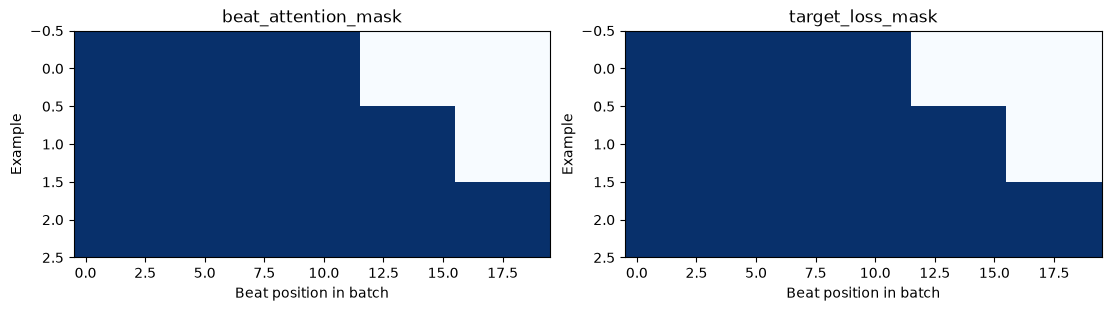

In [3]:
batch=collate_sequences(items)
display(pd.DataFrame([{'group':g,'tensor':k,'shape':list(v.shape),'dtype':str(v.dtype)} for g in ('inputs','targets') for k,v in batch[g].items()]))
print('Real lengths:',[len(i['metadata']['beat_indices']) for i in items])
print('Shortest-only batch:',list(collate_sequences(items[:1])['inputs']['beat_attention_mask'].shape))
fig,axes=plt.subplots(1,2,figsize=(11,3),layout='constrained')
for ax,key,group in zip(axes,['beat_attention_mask','target_loss_mask'],['inputs','targets']):
    ax.imshow(batch[group][key].numpy(),aspect='auto',vmin=0,vmax=1,cmap='Blues')
    ax.set(title=key,xlabel='Beat position in batch',ylabel='Example')
plt.show()
mask=batch['inputs']['beat_attention_mask']
assert (batch['targets']['target_chord_ids'][~mask]==-100).all()
assert not batch['targets']['target_loss_mask'][~mask].any()
assert not batch['inputs']['melody_note_mask'][~mask].any()
assert batch['inputs']['melody_attention_mask'][~mask][:,0].all()


## Offset storage, length distribution and source coverage

NPZ shards contain concatenated real beats plus offsets. They contain no globally
padded beat positions and never deserialize pickle objects. Note slots remain
training-derived and no real melody notes are truncated.

,array,shape,dtype
0,inputs__basic_chord_ids,[64],int64
1,inputs__basic_root_ids,[64],int64
2,inputs__basic_quality_ids,[64],int64
3,inputs__previous_basic_chord_ids,[64],int64
4,inputs__next_basic_chord_ids,[64],int64
5,inputs__key_ids,[64],int64
6,inputs__mode_ids,[64],int64
7,inputs__key_confidence_ids,[64],int64
8,inputs__roman_ids,[64],int64
9,inputs__harmonic_function_ids,[64],int64


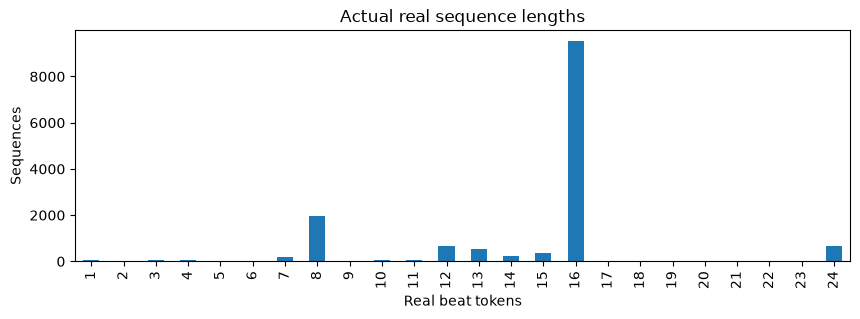

,check,result
0,all_passed,True
1,split_isolation,True
2,train_only_vocabulary,True
3,all_shards_round_trip_verified,True
4,all_real_inputs_and_targets_equal_source_encoder,True
5,no_note_truncation,True
6,no_new_beat_exclusions,True
7,source_beats_lost,0
8,source_beats_duplicated,0
9,eligible_beats,212169


Full-data source comparison and readable CSV round-trip: passed


In [4]:
index=read('train_sequences.json')
with np.load(OUT/index['shards'][0]['path'],allow_pickle=False) as shard:
    display(pd.DataFrame([{'array':k,'shape':list(shard[k].shape),'dtype':str(shard[k].dtype)} for k in shard.files]))
    assert all(not shard[k].dtype.hasobject for k in shard.files)
    assert shard['inputs__beat_attention_mask'].all()
lengths={}
for split,report in stats.items():
    for size,count in report['sequence_length_distribution'].items():lengths[int(size)]=lengths.get(int(size),0)+count
pd.Series(lengths).sort_index().plot.bar(figsize=(10,3),title='Actual real sequence lengths',xlabel='Real beat tokens',ylabel='Sequences')
plt.show()
validation=read('preprocessing_validation_report.json')
display(pd.DataFrame([{'check':k,'result':v} for k,v in validation.items() if k!='source_sha256']))
assert validation['source_beats_lost']==validation['source_beats_duplicated']==0
print('Full-data source comparison and readable CSV round-trip:',read('readable_csv_validation.json')['status'])
